In [25]:
import os 
from tqdm import tqdm 
import tensorflow as tf
import keras
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
import numpy as np

In [26]:
DATA_PATH_TRAINING = ('../data/Training/')

x = []
y = []
counter = 0

classes = os.listdir(DATA_PATH_TRAINING)
print(classes)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [27]:
img_rows, img_cols = 150, 150
print(img_rows, img_cols)

150 150


## Preprocessing

### Training

In [28]:
for class_name in os.listdir(DATA_PATH_TRAINING):
    for fileName in tqdm(os.listdir(f"{DATA_PATH_TRAINING}{class_name}")):
        path = f"{DATA_PATH_TRAINING}{class_name}/{fileName}"
        label = counter

        image = tf.keras.preprocessing.image.load_img(path, target_size=(img_rows, img_cols), color_mode='grayscale')
        image = tf.keras.preprocessing.image.img_to_array(image)

        x.append(image)
        y.append(label)

    counter += 1

 31%|███       | 432/1400 [00:00<00:02, 460.50it/s]


KeyboardInterrupt: 

In [ ]:
x = np.array(x)
y = np.array(y)

x = x.astype('float32') / 255.0

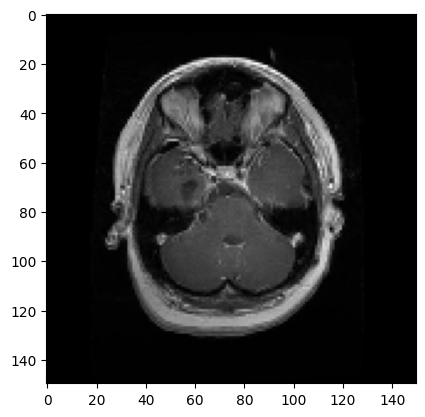

In [ ]:
plt.imshow(x[664], cmap='gray')

### Testing

In [ ]:
DATA_PATH_TESTING = ('../data/Testing/')

X_test = []
y_test = []
counter = 0

classes_test = os.listdir(DATA_PATH_TESTING)
print(classes_test)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
for class_name_test in os.listdir(DATA_PATH_TESTING):
    for fileName_test in tqdm(os.listdir(f"{DATA_PATH_TESTING}{class_name_test}")):
        path_test = f"{DATA_PATH_TESTING}{class_name_test}/{fileName_test}"
        label_test = counter

        image = tf.keras.preprocessing.image.load_img(path_test, target_size=(img_rows, img_cols), color_mode='grayscale')
        image = tf.keras.preprocessing.image.img_to_array(image)

        X_test.append(image)
        y_test.append(label_test)

    counter += 1

100%|██████████| 400/400 [00:00<00:00, 481.59it/s]


In [ ]:
X_test = np.array(X_test)
y_test = np.array(y_test)

X_test = X_test.astype('float32') / 255.0

y_test = keras.utils.to_categorical(y_test, num_classes=4)

## Split Data Train & Val (80 : 20)

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    x, y, test_size=0.2, random_state=42
)

# Ubah label jadi One Hot Encoder
y_train = keras.utils.to_categorical(y_train, num_classes=4)
y_test = keras.utils.to_categorical(y_test, num_classes=4)
y_val = keras.utils.to_categorical(y_val, num_classes=4)

## Layer

In [ ]:
model = keras.Sequential([
    keras.layers.Conv2D(32, (4,4), activation='relu', input_shape=(img_rows,img_cols, 1)),
    keras.layers.MaxPooling2D(pool_size=(3,3)),
    keras.layers.Conv2D(64, (4,4), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(3,3)),
    keras.layers.Conv2D(128, (4,4), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(3,3)),
    keras.layers.Flatten(),
    keras.layers.Dense(512, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(4, activation='softmax'),
])

print(model.summary())

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 147, 147, 32)      544       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 49, 49, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 46, 46, 64)        32832     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 15, 15, 64)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 12, 12, 128)       131200    
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 4, 4, 128)        0

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience = 5,
    restore_best_weights=True
)

checkpoint = keras.callbacks.ModelCheckpoint(
    filepath='../models/brain_tumor_model_new.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min'
)

history = model.fit(
    X_train, y_train, batch_size=32, validation_data=(X_val, y_val), epochs=30, callbacks=[early_stopping, checkpoint]
)

## Model Prediction & Evaluation

In [ ]:
score = model.evaluate(X_test, y_test)
print(f"Test Loss = {score[0]}")
print(f"Test Accuracy : {score[1]}")

In [ ]:
predictions = model.predict(X_test)
predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(y_test, axis=1)

plt.figure(figsize=(10,6))

for i in range(9): 
    ax = plt.subplot(3, 3, i+1)
    ax.imshow(X_test[i], cmap='gray')
    ax.axis('off')
    ax.text(f'Actual : {classes[actual_labels[i]]}\nPredicted : {classes[predicted_labels[i]]}', fontsize=10)

plt.tight_layout()

for i in range(9): 
    print(f'Actual : {classes[actual_labels[i]]}\t\t | Predicted : {classes[predicted_labels[i]]}')

In [ ]:
plt.figure(figsize=(18, 6))

# Accuracy Plotting
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

# Loss Plotting
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.show()

## For Use without Training

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
MODEL_PATH = PROJECT_ROOT / "models" / "brain_tumor_model_new.keras"

model_testing = tf.keras.models.load_model(MODEL_PATH)

## Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

y_true = np.argmax(y_test, axis=1)

y_pred_prob = model_testing.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - External Testing")
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))